# 1. Who entered when, and what happens to each group month by month?

**Week 4, Thursday. Chapter 1 of 3.** This notebook counts the twelve-row card by hand before any
pivot touches sixty thousand members, so the paradox of a flat blend over falling cohorts is
visible in rows a reader can see all at once.

**Who needs the answer.** The head of Gold, Chennai, who signs the fix-first call on Friday.

**The questions on the way.** What is a cohort, how is retention counted per member, what does
the blend average over, and what number does the dashboard print when the mix shifts.

**The case label.** Illustrative case: the company is real, the situation and the data are
synthetic, built for this class.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
import csv, pathlib
from collections import Counter

DATA = pathlib.Path("../data")
members = pd.read_csv(DATA / "C2_W04_D04_members_STUDENT.csv")
member_months = pd.read_csv(DATA / "C2_W04_D04_member_months_STUDENT.csv")
events = pd.read_csv(DATA / "C2_W04_D04_events_STUDENT.csv")
twelve = pd.read_csv(DATA / "C2_W04_D04_twelve_rows_STUDENT.csv")

PASS_COUNT = {"pass": 0, "fail": 0}


def check(label, condition, detail=""):
    ok = bool(condition)
    PASS_COUNT["pass" if ok else "fail"] += 1
    word = "PASS" if ok else "FAIL"
    print(f"{word}  {label}" + (f"  ({detail})" if detail else ""))
    return ok


def check_summary():
    print(f"\n{'PASS' if PASS_COUNT['fail'] == 0 else 'FAIL'}  "
          f"{PASS_COUNT['pass']} checks passed and {PASS_COUNT['fail']} failed in this notebook.")


print(f"loaded: {len(members)} members, {len(member_months)} member-months, "
      f"{len(events)} events, {len(twelve)} twelve-row members")

loaded: 60000 members, 248000 member-months, 225076 events, 12 twelve-row members


## What are the three signup months in the twelve rows?

The twelve rows carry three cohorts: May 2026 (four members), June 2026 (three) and the August
sale (five). Each row has an orders flag per calendar month after signup, with blanks where that
month has not happened yet by September. Print the card first, so every later number is
checkable by eye.

In [2]:
print(twelve.to_string(index=False))
check("twelve rows load", len(twelve) == 12, detail=f"actual {len(twelve)}")

member_id cohort_month  orders_m1  orders_m2  orders_m3  orders_m4
 ZG000101      2026-05          1        1.0        1.0        1.0
 ZG000102      2026-05          1        1.0        0.0        1.0
 ZG000103      2026-05          1        0.0        0.0        0.0
 ZG000104      2026-05          0        0.0        0.0        0.0
 ZG000201      2026-06          1        1.0        1.0        NaN
 ZG000202      2026-06          1        0.0        1.0        NaN
 ZG000203      2026-06          0        0.0        0.0        NaN
 ZG000301      2026-08          1        NaN        NaN        NaN
 ZG000302      2026-08          1        NaN        NaN        NaN
 ZG000303      2026-08          0        NaN        NaN        NaN
 ZG000304      2026-08          0        NaN        NaN        NaN
 ZG000305      2026-08          0        NaN        NaN        NaN
PASS  twelve rows load  (actual 12)


True

## How many of each cohort returned in month one and month two?

**Predict before you run.** Say the counts aloud, by cohort: May members with an order in month
one; May members with an order in month two; June members with an order in month one; June in
month two; August in month one.

In [3]:
m1_by = twelve.groupby("cohort_month")["orders_m1"].sum().astype(int)
m2_by = twelve.groupby("cohort_month")["orders_m2"].sum().astype(int)
print("month-one counts, by cohort:")
print(m1_by)
print()
print("month-two counts, by cohort:")
print(m2_by)
check("May month-one is 3 of 4", m1_by.loc["2026-05"] == 3)
check("May month-two is 2 of 4", m2_by.loc["2026-05"] == 2)
check("June month-one is 2 of 3", m1_by.loc["2026-06"] == 2)
check("June month-two is 1 of 3", m2_by.loc["2026-06"] == 1)
check("August month-one is 2 of 5", m1_by.loc["2026-08"] == 2)

month-one counts, by cohort:
cohort_month
2026-05    3
2026-06    2
2026-08    2
Name: orders_m1, dtype: int64

month-two counts, by cohort:
cohort_month
2026-05    2
2026-06    1
2026-08    0
Name: orders_m2, dtype: int64
PASS  May month-one is 3 of 4
PASS  May month-two is 2 of 4
PASS  June month-one is 2 of 3
PASS  June month-two is 1 of 3
PASS  August month-one is 2 of 5


True

## What happened in September, and what is the blended rate on these twelve?

September is month four for May members, month three for June members and month one for the
August cohort, so the blended rate takes one column per cohort. Count the orders per cohort for
September, then the twelve-row blend.

**Predict before you run.** Which of these three fits the twelve rows: 3 of 12, 6 of 12 or 9 of 12?

In [4]:
may_sep = int(twelve[twelve["cohort_month"] == "2026-05"]["orders_m4"].sum())
jun_sep = int(twelve[twelve["cohort_month"] == "2026-06"]["orders_m3"].sum())
aug_sep = int(twelve[twelve["cohort_month"] == "2026-08"]["orders_m1"].sum())
sep = may_sep + jun_sep + aug_sep
print(f"May members ordering in September (m4): {may_sep} of 4")
print(f"June members ordering in September (m3): {jun_sep} of 3")
print(f"August members ordering in September (m1): {aug_sep} of 5")
print(f"twelve-row blend for September: {sep} of 12 = {sep / 12:.2f}")
check("September blend on the twelve rows is 6 of 12", sep == 6)
check("the rate reads 0.50 on the twelve rows", abs(sep / 12 - 0.50) < 0.01)

May members ordering in September (m4): 2 of 4
June members ordering in September (m3): 2 of 3
August members ordering in September (m1): 2 of 5
twelve-row blend for September: 6 of 12 = 0.50
PASS  September blend on the twelve rows is 6 of 12
PASS  the rate reads 0.50 on the twelve rows


True

## What happens to the twelve-row blend when a bigger young cohort joins?

Suppose August had been three times the size, with the same month-one share. The twelve-row card
would now carry three Augusts for every one May and June. The toy below (invented) runs the
counterfactual: a batch A of 100 at 50 percent in month-one, then a batch B of 400 members with
52.5 percent, and the blended rate stays at 50 percent while A has fallen to 40.

In [5]:
# Toy A and B (invented, R1), from the deck
toy_a_last = {"members": 100, "retained": 50}
toy_a_this = {"members": 100, "retained": 40}
toy_b_this = {"members": 400, "retained": 210}

blend_last = toy_a_last["retained"] / toy_a_last["members"]
blend_this_a = toy_a_this["retained"] / toy_a_this["members"]
blend_this = ((toy_a_this["retained"] + toy_b_this["retained"])
              / (toy_a_this["members"] + toy_b_this["members"]))

print(f"last month, A alone: {toy_a_last['retained']} of {toy_a_last['members']} = {blend_last:.2f}")
print(f"this month, A alone: {toy_a_this['retained']} of {toy_a_this['members']} = {blend_this_a:.2f}")
print(f"this month, A plus B: {toy_a_this['retained'] + toy_b_this['retained']} of "
      f"{toy_a_this['members'] + toy_b_this['members']} = {blend_this:.2f}")
check("A alone fell from 0.50 to 0.40", abs(blend_this_a - 0.40) < 0.01)
check("A plus B blend is 0.50 even though A fell", abs(blend_this - 0.50) < 0.01)

last month, A alone: 50 of 100 = 0.50
this month, A alone: 40 of 100 = 0.40
this month, A plus B: 250 of 500 = 0.50
PASS  A alone fell from 0.50 to 0.40
PASS  A plus B blend is 0.50 even though A fell


True

## A picture of the toy: A falls, B joins, blend holds

The stacked bar lets the eye read the mix shift in one look. Each bar is a reporting month;
light shading is members present, dark is members retained. The blended rate under each bar is
the dark share over the total.

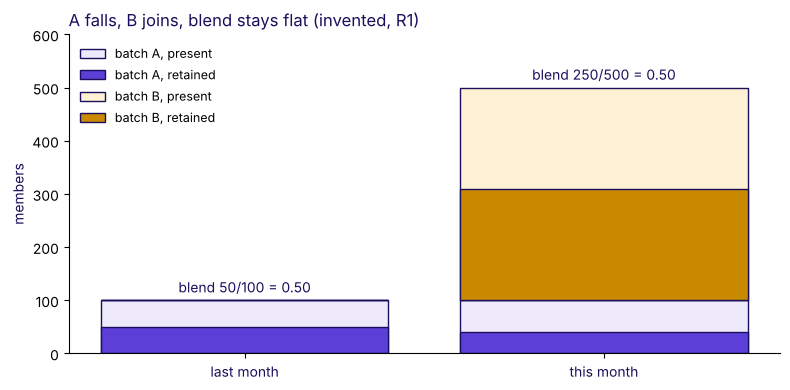

PASS  the stacked chart shows four series


True

In [6]:
import matplotlib.pyplot as plt

xs = [0, 1]
a_mem = [toy_a_last["members"], toy_a_this["members"]]
a_ret = [toy_a_last["retained"], toy_a_this["retained"]]
b_mem = [0, toy_b_this["members"]]
b_ret = [0, toy_b_this["retained"]]

fig, ax = plt.subplots(figsize=(8, 4.0))
ax.bar(xs, a_mem, color="#EEEAFB", edgecolor="#1A0F5C", label="batch A, present")
ax.bar(xs, a_ret, color="#5B3FD6", edgecolor="#1A0F5C", label="batch A, retained")
ax.bar(xs, b_mem, bottom=a_mem, color="#FFF2D4", edgecolor="#1A0F5C", label="batch B, present")
ax.bar(xs, b_ret, bottom=a_mem, color="#C98A00", edgecolor="#1A0F5C", label="batch B, retained")
for x in xs:
    total_mem = a_mem[x] + b_mem[x]
    total_ret = a_ret[x] + b_ret[x]
    if total_mem:
        ax.text(x, total_mem + 15, f"blend {total_ret}/{total_mem} = {total_ret / total_mem:.2f}",
                ha="center", color="#1A0F5C", fontsize=10)
ax.set_xticks(xs)
ax.set_xticklabels(["last month", "this month"], color="#1A0F5C")
ax.set_ylim(0, 600)
ax.set_ylabel("members", color="#1A0F5C")
ax.legend(loc="upper left", fontsize=9, frameon=False)
ax.set_title("A falls, B joins, blend stays flat (invented, R1)", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the stacked chart shows four series", len(ax.patches) >= 4)

## A picture of the twelve rows and the toy

The deck carries the matplotlib figures the figure script wrote. In this notebook, show the same
twelve rows as a tidy frame, so the reader can scroll and verify every count.

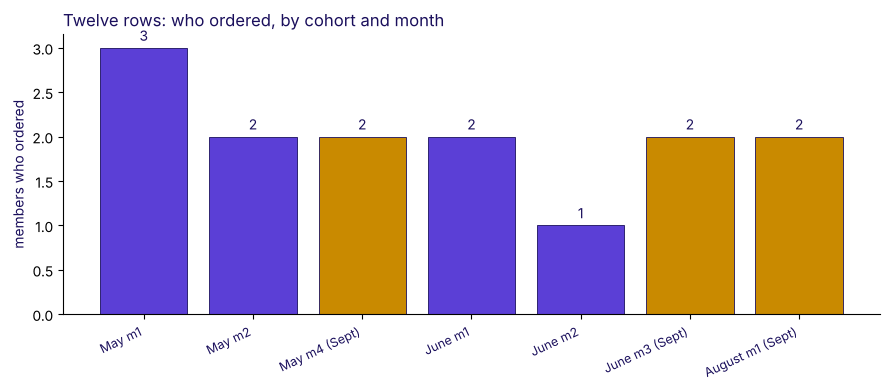

PASS  the chart draws seven bars


True

In [7]:
import matplotlib.pyplot as plt

labels = ["May m1", "May m2", "May m4 (Sept)",
          "June m1", "June m2", "June m3 (Sept)",
          "August m1 (Sept)"]
values = [3, 2, may_sep, 2, 1, jun_sep, aug_sep]
colours = ["#5B3FD6"] * 2 + ["#C98A00"] + ["#5B3FD6"] * 2 + ["#C98A00"] + ["#C98A00"]

fig, ax = plt.subplots(figsize=(9, 4.0))
bars = ax.bar(range(len(labels)), values, color=colours, edgecolor="#1A0F5C", linewidth=0.6)
for i, v in enumerate(values):
    ax.text(i, v + 0.08, str(v), ha="center", color="#1A0F5C", fontsize=10)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=9, color="#1A0F5C")
ax.set_ylabel("members who ordered", color="#1A0F5C")
ax.set_title("Twelve rows: who ordered, by cohort and month", color="#1A0F5C", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the chart draws seven bars", len(bars) == 7)

## What are the Chennai cohort sizes, side by side?

The nine cohorts are drawn as bars so the eye sees the August spike. The August cohort is 2.6
times a normal cohort and is the youngest and lowest-retention row by September.

/tmp/ipykernel_7048/1735752209.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(cohort_sizes.index.astype(str), rotation=25, ha="right",


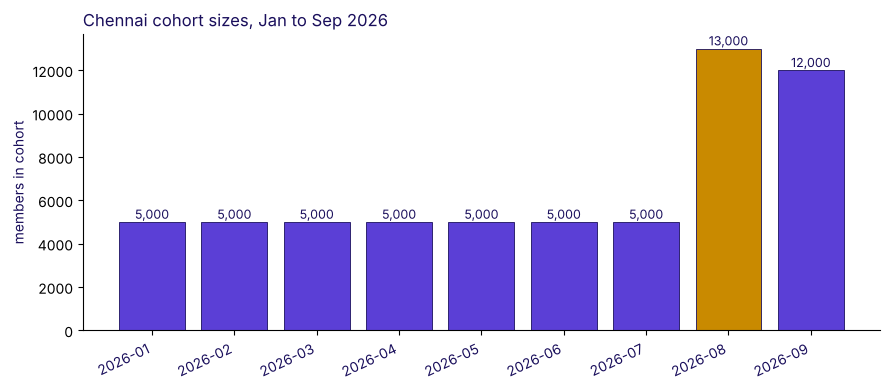

PASS  August is the biggest cohort  (13000 vs max 13000)


True

In [8]:
import matplotlib.pyplot as plt

cohort_sizes = members["cohort_month"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.0))
colours = ["#5B3FD6" if c != "2026-08" else "#C98A00" for c in cohort_sizes.index]
bars = ax.bar(cohort_sizes.index.astype(str), cohort_sizes.values,
              color=colours, edgecolor="#1A0F5C", linewidth=0.6)
for i, v in enumerate(cohort_sizes.values):
    ax.text(i, v + 150, f"{v:,}", ha="center", color="#1A0F5C", fontsize=9)
ax.set_xticklabels(cohort_sizes.index.astype(str), rotation=25, ha="right",
                   color="#1A0F5C", fontsize=10)
ax.set_ylabel("members in cohort", color="#1A0F5C")
ax.set_title("Chennai cohort sizes, Jan to Sep 2026", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("August is the biggest cohort",
      cohort_sizes.loc["2026-08"] == cohort_sizes.max(),
      detail=f"{cohort_sizes.loc['2026-08']} vs max {cohort_sizes.max()}")

## What did the dashboard print, and where does the twelve-row count sit against it?

The dashboard reports 38 percent flat for June, July, August and September 2026 (the ticket).
The twelve-row blend for September is 0.50, five points above the dashboard. The dashboard
averages over 48,000 pre-signed members at those ages, not twelve; the shape is the same.
Chapter 2 reproduces the dashboard's number on the full data and decomposes it.

In [9]:
dashboard = 0.38
twelve_row = sep / 12
gap = twelve_row - dashboard
print(f"dashboard (reported, Chennai Sept 2026): {dashboard:.2f}")
print(f"twelve-row blend for September: {twelve_row:.2f}")
print(f"gap on twelve rows: {gap:+.2f}")
check("the twelve-row blend is at least five points above the dashboard",
      gap >= 0.05, detail=f"gap {gap:.3f}")
check_summary()

dashboard (reported, Chennai Sept 2026): 0.38
twelve-row blend for September: 0.50
gap on twelve rows: +0.12
PASS  the twelve-row blend is at least five points above the dashboard  (gap 0.120)

PASS  14 checks passed and 0 failed in this notebook.


## What the next notebook adds.

Notebook 02 pivots the full member_months table into the triangle on sixty thousand members,
draws every cohort's curve, decomposes the blend into cohort size and cohort rate, and finds the
sale cohort in an empty your-turn cell. The toy you ran here is the shape; the full data makes
it a number.